<a href="https://colab.research.google.com/github/JuanTorresCol/Convolutional-Neural-Networks-/blob/main/CNN_ini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Assignment 2- CNN**

In [1]:
# Imports
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist, cifar10
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
# Load MNIST: handwritten grayscale digits (0-9), used here as an OCR-style dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Train: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)


1.a. start with creating a visualization of input data

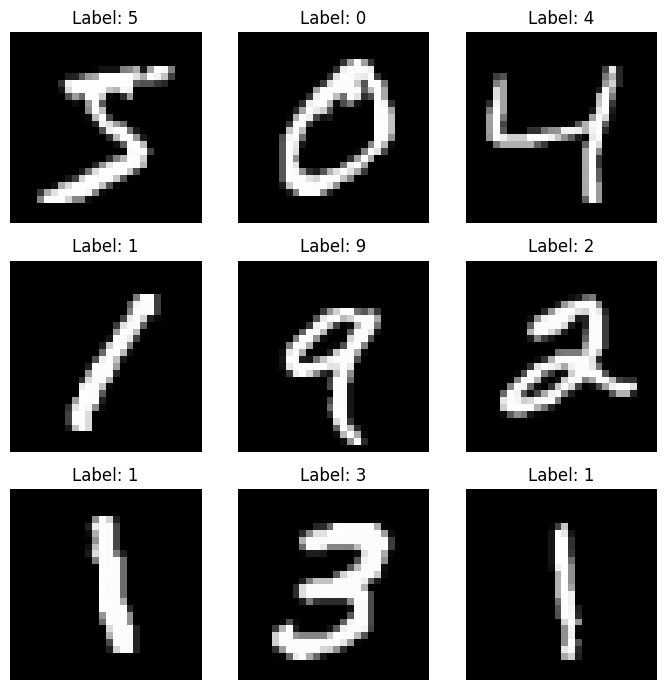

In [3]:
# Visualize the first 9 MNIST images
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
# Add the grayscale channel dimension (channels-last format)
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]
input_shape = (28, 28, 1)

In [5]:
# Normalize pixel values and one-hot encode class labels
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

1.b. Create a CNN model with 4 convolution layers in which two of them have 32 and two of them have 64 filters. The fully connected layer has one hidden layer (512 nodes). Draw the Learning curve. What is your understanding from learning curve? Batch size=128 and epochs=20

In [6]:
# Four convolutional layers: two with 32 filters and two with 64 filters
mnist_model = keras.Sequential([
    layers.Input(shape=input_shape),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dense(10, activation="softmax")
])
mnist_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,606,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,676,266 (6.39 MB)

 Trainable params: 1,676,266 (6.39 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
mnist_model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)
hist = mnist_model.fit(
    X_train, y_train_cat,
    validation_split=0.1,
    batch_size=128,
    epochs=20,
    verbose=1
)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step - accuracy: 0.9473 - loss: 0.1708 - val_accuracy: 0.9840 - val_loss: 0.0552
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9858 - loss: 0.0444 - val_accuracy: 0.9813 - val_loss: 0.0589
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9901 - loss: 0.0308 - val_accuracy: 0.9898 - val_loss: 0.0356
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9928 - loss: 0.0231 - val_accuracy: 0.9910 - val_loss: 0.0365
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9940 - loss: 0.0179 - val_accuracy: 0.9912 - val_loss: 0.0336
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9955 - loss: 0.0136 - val_accuracy: 0.9913 - val_loss: 0.0385
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9958 - loss: 0.0127 - val_accuracy: 0.9898 - val_loss: 0.0451
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9963 - loss: 0.0113 - val_accuracy: 

In [8]:
# Evaluate on the held-out MNIST test set
scores = mnist_model.evaluate(X_test, y_test_cat, verbose=0)
print(f"MNIST test loss: {scores[0]:.4f}")
print(f"MNIST test accuracy: {scores[1] * 100:.2f}%")

MNIST test loss: 0.0293
MNIST test accuracy: 99.25%


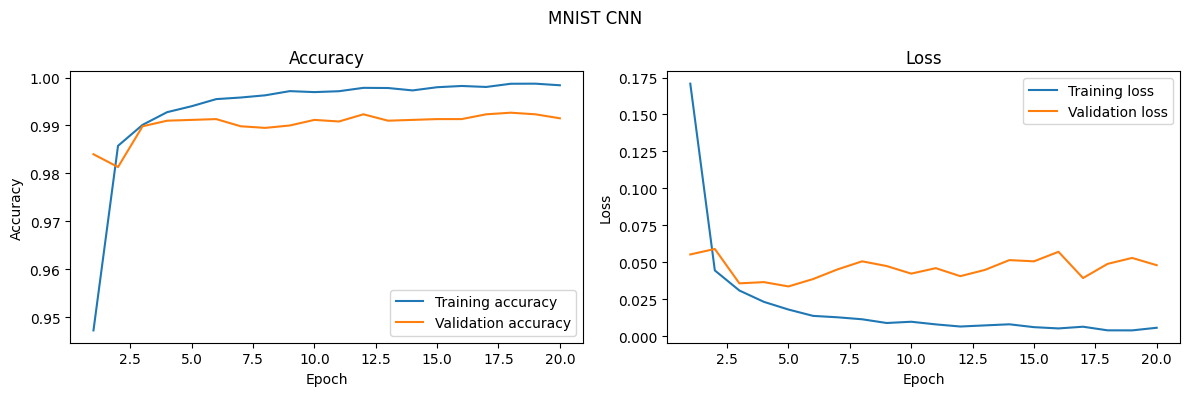

In [9]:
def learning_curve(history, title="Learning curve"):
    # Plot training and validation accuracy/loss
    epochs = range(1, len(history.history["accuracy"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history.history["accuracy"], label="Training accuracy")
    axes[0].plot(epochs, history.history["val_accuracy"], label="Validation accuracy")
    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[1].plot(epochs, history.history["loss"], label="Training loss")
    axes[1].plot(epochs, history.history["val_loss"], label="Validation loss")
    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

learning_curve(hist, "MNIST CNN")

In [ ]:
# Interpretation:
# If training and validation accuracy both rise and remain close, while both losses
# decrease, the model is learning and generalizing reasonably well. If training
# accuracy keeps rising but validation accuracy plateaus/falls (and validation loss
# rises), the model is overfitting. MNIST is a relatively simple dataset, so this
# CNN would normally be expected to achieve high test accuracy.

**Part 2- CIFAR10**

In [11]:
# Load CIFAR-10: 50,000 training and 10,000 test RGB images, each 32x32
(X_train, y_train), (X_test, y_test) = cifar10.load_data()
labels = ["airplane", "automobile", "bird", "cat", "deer",
          "dog", "frog", "horse", "ship", "truck"]
print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (50000, 32, 32, 3) (50000, 1)
Test: (10000, 32, 32, 3) (10000, 1)


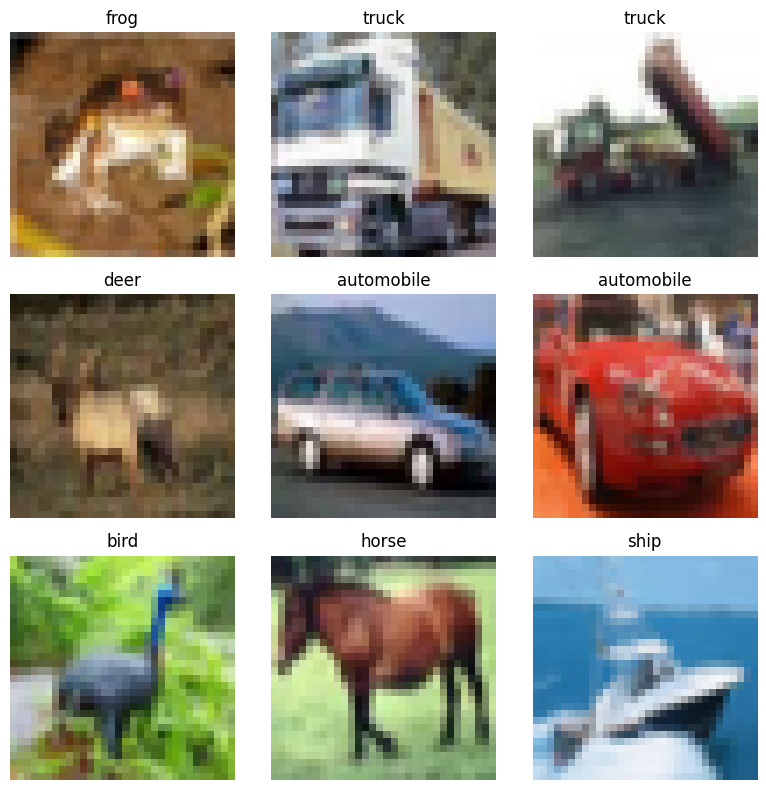

In [12]:
# Plot the first 9 CIFAR-10 training images with their class names
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i])
    ax.set_title(labels[int(y_train[i, 0])])
    ax.axis("off")
plt.tight_layout()
plt.show()

2.b. Apply the pre-processing algorithms that we discussed last week. The augmented images are supposed to be seared by 20%, zoomed by 20% and horizontally flipped. Now, design a CNN model with 4 convolution layers in which two of them have 32 and two of them have 64 filters. The fully connected layer has two hidden layers (512 and 256 nodes respectively). Draw the Learning curve. What is your understanding from learning curve?

In [13]:
# One-hot encode labels
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

# Augmentation: shear by 20%, zoom by 20%, and horizontal flip
# The generator also rescales pixel values to [0, 1].
datagen = ImageDataGenerator(
    rescale=1.0/255.0,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.1
)
train_generator = datagen.flow(
    X_train, y_train_cat,
    batch_size=128,
    subset="training",
    seed=SEED,
    shuffle=True
)
# Use a non-augmented validation set so validation metrics are comparable.
validation_datagen = ImageDataGenerator(
    rescale=1.0/255.0,
    validation_split=0.1
)
validation_generator = validation_datagen.flow(
    X_train, y_train_cat,
    batch_size=128,
    subset="validation",
    seed=SEED,
    shuffle=False
)

# CNN with four convolution layers (32, 32, 64, 64) and dense layers (512, 256)
def build_cifar_cnn(use_dropout=False):
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.5) if use_dropout else layers.Activation("linear"),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5) if use_dropout else layers.Activation("linear"),
        layers.Dense(10, activation="softmax")
    ])
    return model

# Keras 3 removed the old SGD argument. InverseTimeDecay reproduces
# the requested inverse-time learning-rate decay: lr = 0.005/(1 + 1e-6*step).
lr_schedule = keras.optimizers.schedules.InverseTimeDecay(
    initial_learning_rate=0.005,
    decay_steps=1,
    decay_rate=1e-6,
    staircase=False
)
sgd_optimizer = SGD(learning_rate=lr_schedule, momentum=0.9)

cifar_model = build_cifar_cnn(use_dropout=False)
cifar_model.compile(
    optimizer=sgd_optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
hist = cifar_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    verbose=1
)

# Evaluate on unaugmented, normalized test images
X_test_scaled = X_test.astype("float32") / 255.0
cifar_scores = cifar_model.evaluate(X_test_scaled, y_test_cat, verbose=0)
print(f"CIFAR-10 CNN test accuracy: {cifar_scores[1] * 100:.2f}%")

Epoch 1/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 43s 103ms/step - accuracy: 0.2390 - loss: 2.0829 - val_accuracy: 0.3350 - val_loss: 1.8545
Epoch 2/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.3878 - loss: 1.7054 - val_accuracy: 0.4588 - val_loss: 1.5213
Epoch 3/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.4562 - loss: 1.5123 - val_accuracy: 0.4890 - val_loss: 1.4141
Epoch 4/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 76ms/step - accuracy: 0.4928 - loss: 1.4151 - val_accuracy: 0.4970 - val_loss: 1.3620
Epoch 5/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 76ms/step - accuracy: 0.5215 - loss: 1.3383 - val_accuracy: 0.5412 - val_loss: 1.2772
Epoch 6/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.5490 - loss: 1.2683 - val_accuracy: 0.5662 - val_loss: 1.1760
Epoch 7/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 27s 77ms/step - accuracy: 0.5706 - loss: 1.2091 - val_accuracy: 0.5884 - val_loss: 1.1658
Epoch 8/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.5904 - loss: 1.1545 -

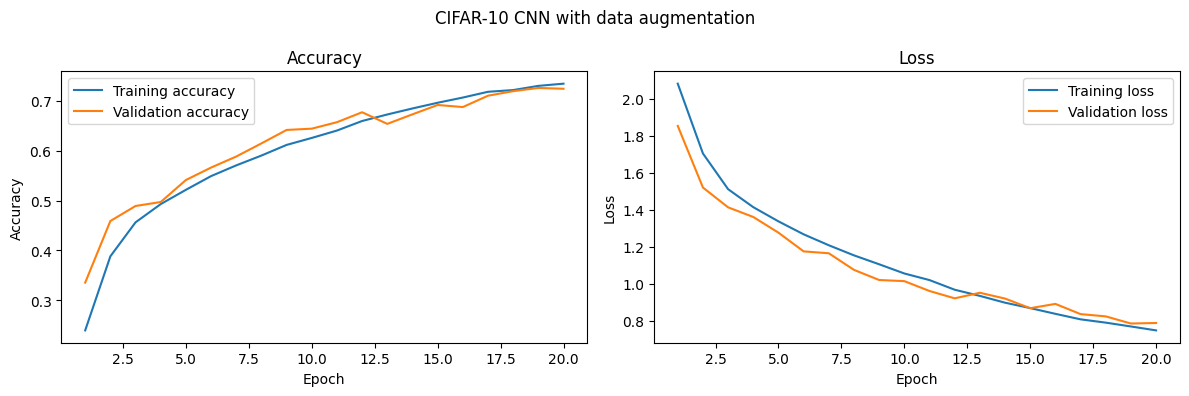

In [14]:
learning_curve(hist, "CIFAR-10 CNN with data augmentation")

In [ ]:
# Interpretation / issue:
# Compare training and validation curves. A common issue is overfitting: training
# accuracy continues to improve while validation accuracy stops improving, and
# validation loss may increase. The gap indicates that the network is memorizing
# training examples instead of generalizing to unseen images. Data augmentation
# helps, but a relatively large dense classifier can still overfit.

In [15]:
# 2.c Recommendation: Dropout regularization (50%) in the fully connected layers.
# It randomly disables a fraction of activations during training, reducing
# co-adaptation and helping the model generalize.
dropout_model = build_cifar_cnn(use_dropout=True)
dropout_model.compile(
    optimizer=SGD(learning_rate=lr_schedule, momentum=0.9),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
dropout_hist = dropout_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=20,
    verbose=1
)
dropout_scores = dropout_model.evaluate(X_test_scaled, y_test_cat, verbose=0)
print(f"CIFAR-10 CNN + dropout test accuracy: {dropout_scores[1] * 100:.2f}%")

Epoch 1/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 35s 90ms/step - accuracy: 0.1634 - loss: 2.2186 - val_accuracy: 0.2856 - val_loss: 1.9624
Epoch 2/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 34s 78ms/step - accuracy: 0.2819 - loss: 1.9369 - val_accuracy: 0.3952 - val_loss: 1.6790
Epoch 3/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 78ms/step - accuracy: 0.3686 - loss: 1.7191 - val_accuracy: 0.4652 - val_loss: 1.4982
Epoch 4/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.4148 - loss: 1.5996 - val_accuracy: 0.4796 - val_loss: 1.4323
Epoch 5/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.4464 - loss: 1.5232 - val_accuracy: 0.5158 - val_loss: 1.3535
Epoch 6/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 80ms/step - accuracy: 0.4690 - loss: 1.4643 - val_accuracy: 0.5216 - val_loss: 1.3063
Epoch 7/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.4901 - loss: 1.4139 - val_accuracy: 0.5382 - val_loss: 1.2820
Epoch 8/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 28s 80ms/step - accuracy: 0.5085 - loss: 1.3620 - 

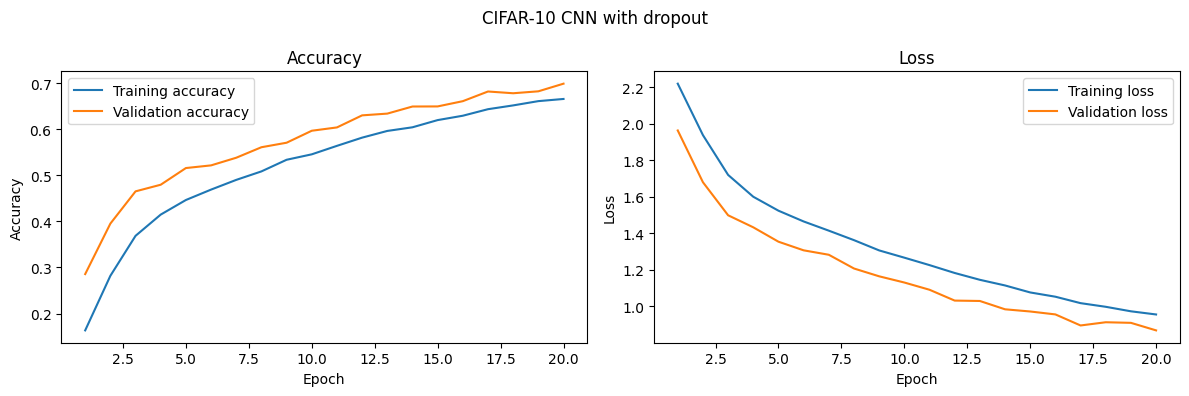

In [16]:
learning_curve(dropout_hist, "CIFAR-10 CNN with dropout")

In [17]:
# 2.d Transfer learning model 1: VGG16 pretrained on ImageNet.
# Resize CIFAR-10 images to 96x96 because ImageNet models expect larger inputs.
# Keep the pretrained convolutional base frozen and train a new classification head.
def make_transfer_model(base_name):
    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.Resizing(96, 96)(inputs)
    if base_name == "VGG16":
        x = layers.Lambda(vgg_preprocess)(x)
        base = VGG16(weights="imagenet", include_top=False, input_shape=(96, 96, 3))
    elif base_name == "ResNet50":
        x = layers.Lambda(resnet_preprocess)(x)
        base = ResNet50(weights="imagenet", include_top=False, input_shape=(96, 96, 3))
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name=base_name + "_CIFAR10")
    return model

vgg_model = make_transfer_model("VGG16")
vgg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Augment raw [0,255] images. Preprocessing is performed inside the model.
transfer_datagen = ImageDataGenerator(
    shear_range=0.2, zoom_range=0.2, horizontal_flip=True,
    validation_split=0.1
)
vgg_train = transfer_datagen.flow(
    X_train, y_train_cat, batch_size=128, subset="training",
    seed=SEED, shuffle=True
)
transfer_val_datagen = ImageDataGenerator(validation_split=0.1)
vgg_val = transfer_val_datagen.flow(
    X_train, y_train_cat, batch_size=128, subset="validation",
    seed=SEED, shuffle=False
)
vgg_hist = vgg_model.fit(
    vgg_train, validation_data=vgg_val, epochs=20, verbose=1
)
vgg_scores = vgg_model.evaluate(X_test, y_test_cat, verbose=0)
print(f"VGG16 test accuracy: {vgg_scores[1] * 100:.2f}%")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 56s 142ms/step - accuracy: 0.6333 - loss: 1.3183 - val_accuracy: 0.7886 - val_loss: 0.6311
Epoch 2/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 43s 123ms/step - accuracy: 0.7339 - loss: 0.7851 - val_accuracy: 0.8130 - val_loss: 0.5618
Epoch 3/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 83s 127ms/step - accuracy: 0.7609 - loss: 0.7061 - val_accuracy: 0.8206 - val_loss: 0.5326
Epoch 4/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 42s 119ms/step - accuracy: 0.7762 - loss: 0.6503 - val_accuracy: 0.8278 - val_loss: 0.5237
Epoch 5/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 43s 122ms/step - accuracy: 0.7829 - loss: 0.6270 - val_accuracy: 0.8254 - val_loss: 0.5121
Epoch 6/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 43s 122ms/step - accuracy: 0.7925 - loss: 0.6037 - val_accuracy: 0.8308 - val_loss: 0.4951
Epoch 7/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 43s 123ms/step - accuracy: 0.7983 - loss: 0.5839 - val_accuracy: 0.8310 - val_loss: 0.5011
Epoch 8/20
352/352 ━━━━━━━━━━━━━

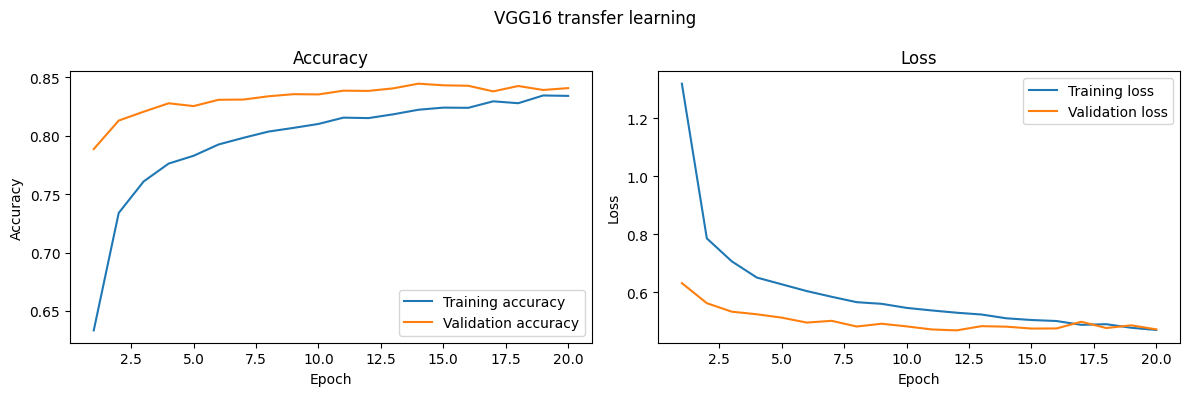

In [18]:
learning_curve(vgg_hist, "VGG16 transfer learning")

In [19]:
# Final VGG16 test-set evaluation
vgg_model.evaluate(X_test, y_test_cat, verbose=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.8410 - loss: 0.4884


[0.4883956015110016, 0.8410000205039978]

In [20]:
# Transfer learning model 2: ResNet50 pretrained on ImageNet
resnet_model = make_transfer_model("ResNet50")
resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
resnet_hist = resnet_model.fit(
    vgg_train, validation_data=vgg_val, epochs=20, verbose=1
)
resnet_scores = resnet_model.evaluate(X_test, y_test_cat, verbose=0)
print(f"ResNet50 test accuracy: {resnet_scores[1] * 100:.2f}%")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 63s 142ms/step - accuracy: 0.7485 - loss: 0.7627 - val_accuracy: 0.8480 - val_loss: 0.4387
Epoch 2/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 36s 103ms/step - accuracy: 0.8021 - loss: 0.5758 - val_accuracy: 0.8578 - val_loss: 0.4095
Epoch 3/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 37s 104ms/step - accuracy: 0.8142 - loss: 0.5381 - val_accuracy: 0.8646 - val_loss: 0.4013
Epoch 4/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 38s 107ms/step - accuracy: 0.8279 - loss: 0.4959 - val_accuracy: 0.8628 - val_loss: 0.3853
Epoch 5/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 37s 104ms/step - accuracy: 0.8328 - loss: 0.4824 - val_accuracy: 0.8614 - val_loss: 0.3972
Epoch 6/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 37s 104ms/step - accuracy: 0.8363 - loss: 0.4647 - val_accuracy: 0.8700 - val_loss: 0.3705
Epoch 7/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step - accuracy: 0.8401 - loss: 0.4518 - val_accuracy: 0.8710 - val_loss: 0.3696
Epoch 8/20
352/352 ━━━━━━━━━━━━━

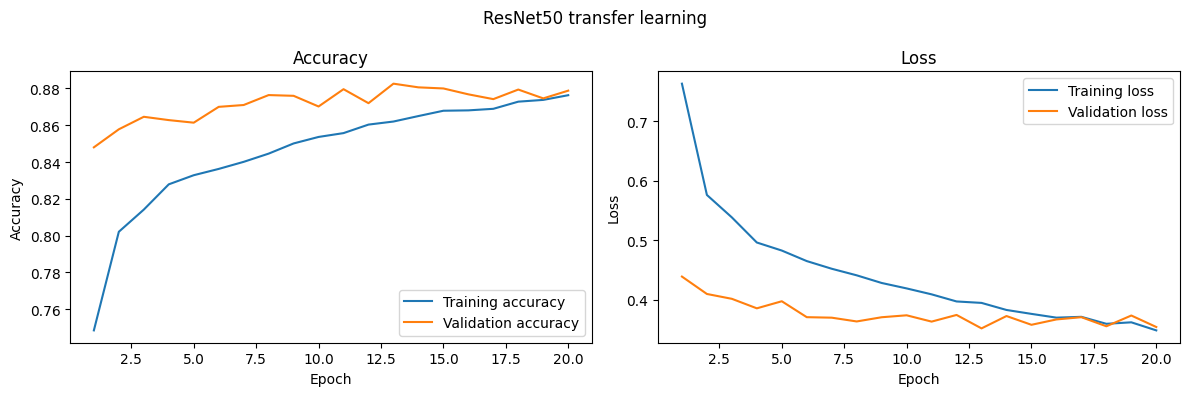

In [21]:
learning_curve(resnet_hist, "ResNet50 transfer learning")

In [22]:
# Model comparison: use the actual test accuracies printed above.
results = {
    "CNN + augmentation": float(cifar_scores[1]),
    "CNN + augmentation + dropout": float(dropout_scores[1]),
    "VGG16 transfer learning": float(vgg_scores[1]),
    "ResNet50 transfer learning": float(resnet_scores[1])
}
for name, accuracy in sorted(results.items(), key=lambda item: item[1], reverse=True):
    print(f"{name}: {accuracy * 100:.2f}%")

best_model = max(results, key=results.get)
print(f"Best test accuracy in this run: {best_model} ({results[best_model] * 100:.2f}%).")

ResNet50 transfer learning: 87.59%
VGG16 transfer learning: 84.10%
CNN + augmentation: 71.30%
CNN + augmentation + dropout: 69.53%
Best test accuracy in this run: ResNet50 transfer learning (87.59%).
